# Global Navigation Satellite System coordinate forecasting at ONSA, Sweden
Goutam Anand · Digvijay Singh · Shan Kuriakose

Advanced Pattern Recognition — Master of Science in Data Science and Artificial Intelligence, South Asian University

One-day-ahead forecasting of daily East, North and Up coordinates. We use the original processed daily coordinate and quality assurance records from [GitHub](https://github.com/goutamsaums/TIME-SERIES/tree/main/data).

Artificial intelligence assistance: ChatGPT helped organize and revise the code. The authors should review and interpret the results.

## Setup
Download the two original data files from GitHub. Exploratory data analysis figures and tables are saved separately from the forecasting and decision results. No exploratory result file is read back or used to fit a model.

In [1]:
from IPython.display import display
import io
import shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
from torch import nn
from statsmodels.tsa.arima.model import ARIMA as AutoregressiveIntegratedMovingAverage
from statsmodels.tsa.seasonal import STL as SeasonalTrendDecomposition
from statsmodels.graphics.tsaplots import (plot_acf as plot_autocorrelation,
                                         plot_pacf as plot_partial_autocorrelation)
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

url = 'https://raw.githubusercontent.com/goutamsaums/TIME-SERIES/main/data/'
results_folder = Path('ONSA_GNSS_Results')
exploratory_folder = results_folder / 'Exploratory_Data_Analysis'
out = results_folder / 'Course_Task_Results'
exploratory_folder.mkdir(parents=True, exist_ok=True)
out.mkdir(parents=True, exist_ok=True)

def download(name):
    r = requests.get(url + name, timeout=120)
    r.raise_for_status()
    return r.content

def save(df, name, folder=out):
    df.to_csv(folder / (name + '.csv'), index=False)
    display(df)

def show_plot(fig, name, folder=out):
    fig.tight_layout()
    fig.savefig(folder / (name + '.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

axes = ['East', 'North', 'Up']

Device: cpu


## Choose the data
Reconstruct coordinates from the integer and residual fields in original coordinate-file format. Use Modified Julian Date for dates and millimetres relative to the beginning of the longest uninterrupted segment. Keep missing days as missing values.

,file,source
0,ONSA1.CSV,https://raw.githubusercontent.com/goutamsaums/...
1,ONSA.qa.gz,https://raw.githubusercontent.com/goutamsaums/...


Archive: 1993-01-02 to 2026-10-24
Observed: 11835 Missing: 514
Availability (%): 95.84
Longest continuous segment: 2110 days


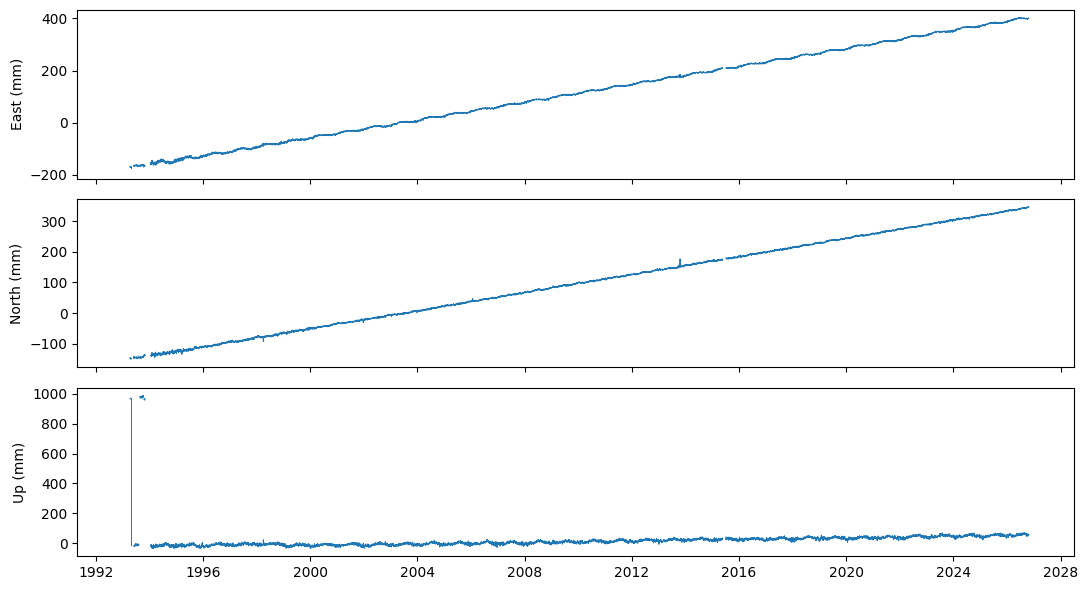

In [2]:
files = ['ONSA1.CSV', 'ONSA.qa.gz']
contents = {name: download(name) for name in files}
save(pd.DataFrame({'file': files, 'source': [url + name for name in files]}),
     'input_sources')
raw = pd.read_csv(io.BytesIO(contents['ONSA1.CSV']), sep=r'\s+')
raw['date'] = pd.to_datetime(raw['__MJD'], unit='D', origin='1858-11-17')
assert raw['date'].is_unique and raw['site'].eq('ONSA').all()
raw = raw.set_index('date').sort_index()

pos = pd.DataFrame(index=raw.index)
for a, (whole, part) in zip(axes, [('_e0(m)', '__east(m)'),
                                   ('____n0(m)', '_north(m)'), ('u0(m)', '____up(m)')]):
    pos[a] = raw[whole] + raw[part]
    pos['formal_uncertainty_' + a] = raw['sig_' + a[0].lower() + '(m)'] * 1000

quality_assurance = pd.read_csv(io.BytesIO(contents['ONSA.qa.gz']), compression='gzip')
quality_assurance['date'] = pd.to_datetime(quality_assurance['date'])
assert quality_assurance['date'].is_unique and quality_assurance['station'].eq('ONSA').all()
quality_assurance = quality_assurance.set_index('date')
pos['accepted_hours'] = quality_assurance['acceptedepochs[unit="hr"]'].where(lambda s: s.between(0,24))
pos['accepted_phase_percent'] = quality_assurance['percentphasesaccepted'].where(lambda s: s.between(0,100))
for a in axes:
    pos['formal_uncertainty_' + a] = pos['formal_uncertainty_' + a].where(lambda s: s > 0)

calendar = pos.reindex(pd.date_range(pos.index.min(), pos.index.max(), freq='D'))
observed = calendar[axes].notna().all(axis=1)
groups = observed.ne(observed.shift()).cumsum()
segments = [g for _, g in calendar[observed].groupby(groups[observed])]
series = max(segments, key=len).copy()
reference = series[axes].iloc[0]
calendar[axes] = (calendar[axes] - reference) * 1000
series = calendar.loc[series.index].copy()
# The data preparation above supplies the observed coordinates for all models.
calendar.to_csv(out / '01_daily_data.csv', index_label='date')

def explore_data(data, continuous_data):
    available = data[axes].notna().all(axis=1)
    print('Archive:', data.index.min().date(), 'to', data.index.max().date())
    print('Observed:', available.sum(), 'Missing:', (~available).sum())
    print('Availability (%):', round(100 * available.mean(), 2))
    print('Longest continuous segment:', len(continuous_data), 'days')
    fig, plot_axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
    for component, axis in zip(axes, plot_axes):
        axis.plot(data.index, data[component], lw=.7)
        axis.set_ylabel(component + ' (mm)')
    show_plot(fig, '01_coordinates', exploratory_folder)

explore_data(calendar, series)

## Decomposition and autocorrelation
Use the first 70 percent of the continuous sequence to examine trend, annual seasonality and remainder using seasonal-trend decomposition. Plot the autocorrelation function and partial autocorrelation function and test the remainder for white noise. These are exploratory diagnostics only; the fitted trend, seasonal component, residuals and their statistics are not passed to any forecast model.

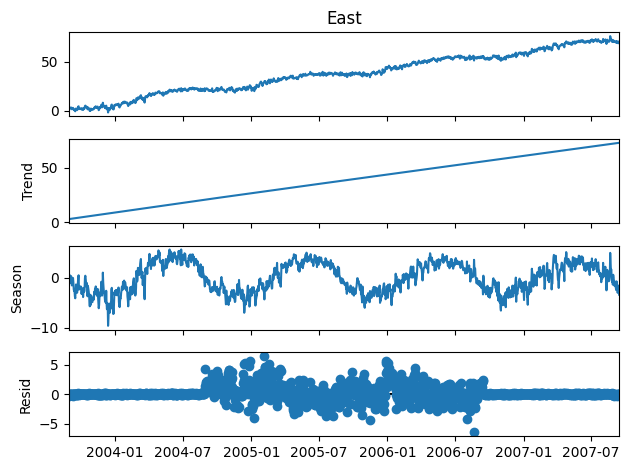

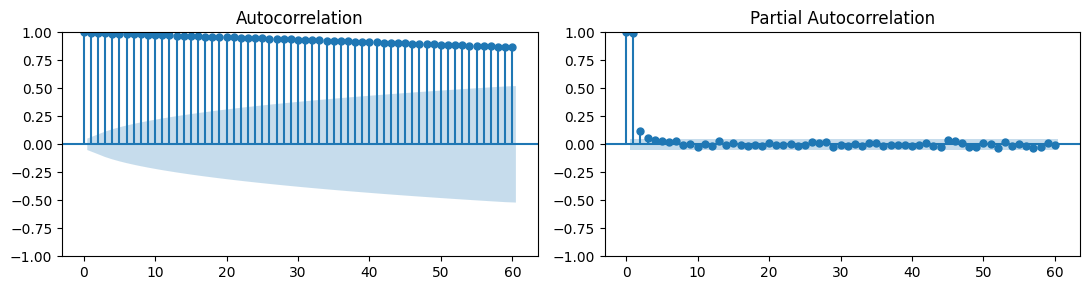

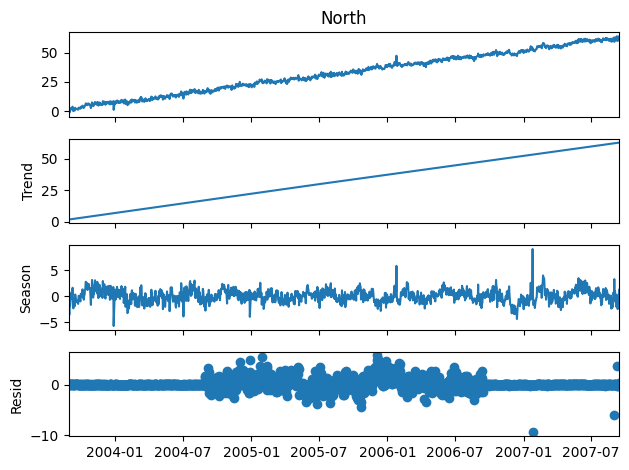

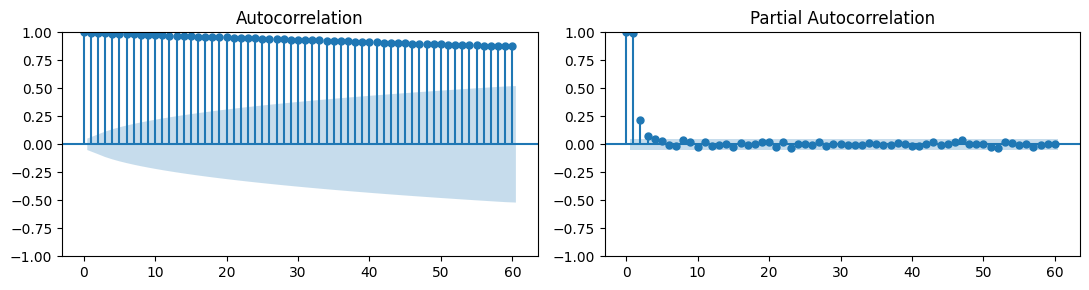

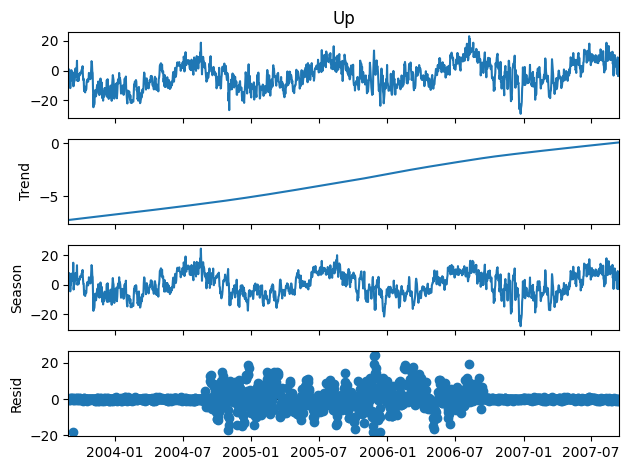

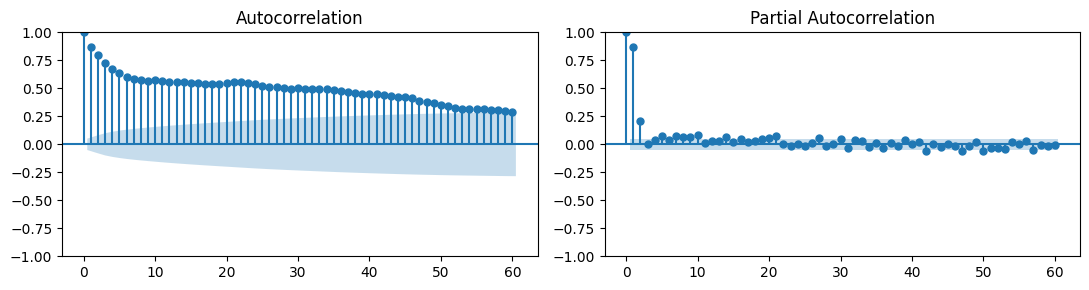

,axis,trend_standard_deviation,seasonal_standard_deviation,remainder_standard_deviation,Ljung_Box_probability_lag20
0,East,20.128205,2.878824,1.234342,0.000000e+00
1,North,17.594022,1.206247,1.113583,0.000000e+00
2,Up,2.253853,7.863577,4.735927,4.069601e-274


In [3]:
def explore_training_data(training_data):
    rows = []
    for a in axes:
        result = SeasonalTrendDecomposition(training_data[a], period=365, robust=True).fit()
        fig = result.plot()
        show_plot(fig, '02_seasonal_trend_decomposition_' + a, exploratory_folder)
        fig, ax = plt.subplots(1, 2, figsize=(11, 3))
        plot_autocorrelation(training_data[a], lags=60, ax=ax[0]); plot_partial_autocorrelation(training_data[a], lags=60, ax=ax[1])
        show_plot(fig, '02_autocorrelation_' + a, exploratory_folder)
        p = acorr_ljungbox(result.resid, lags=[20], return_df=True)['lb_pvalue'].iloc[0]
        rows.append({'axis': a, 'trend_standard_deviation': result.trend.std(),
                     'seasonal_standard_deviation': result.seasonal.std(), 'remainder_standard_deviation': result.resid.std(),
                     'Ljung_Box_probability_lag20': p})
    save(pd.DataFrame(rows), '02_decomposition', exploratory_folder)

explore_training_data(series[axes].iloc[:int(0.70 * len(series))])

## Chronological split
70% training, 15% validation (half for selection, half for calibration) and the remainder for testing. All models use the same test dates. At each forecast origin, earlier observed coordinates may be used, but the target observation may not be used.

,set,start,end,days
0,training,2003-08-30,2007-09-14,1477
1,selection,2007-09-15,2008-02-19,158
2,calibration,2008-02-20,2008-07-26,158
3,test,2008-07-27,2009-06-08,317


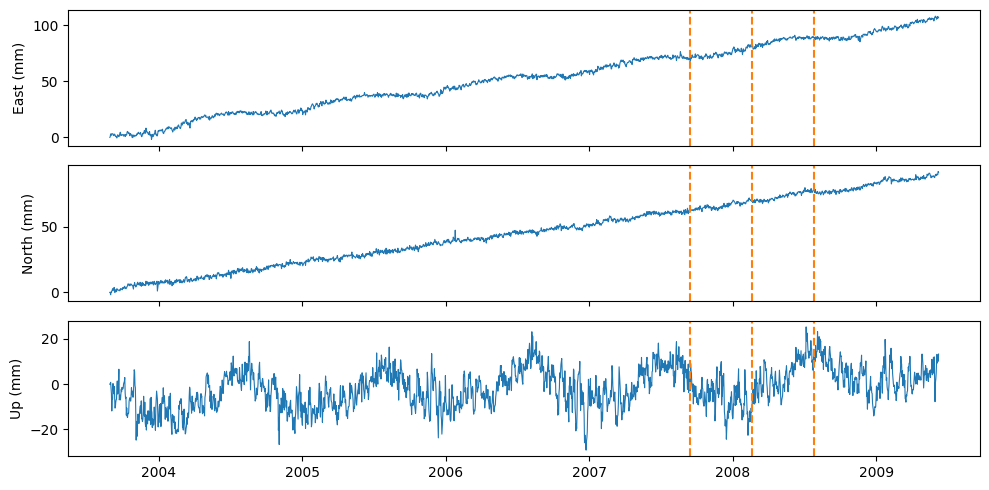

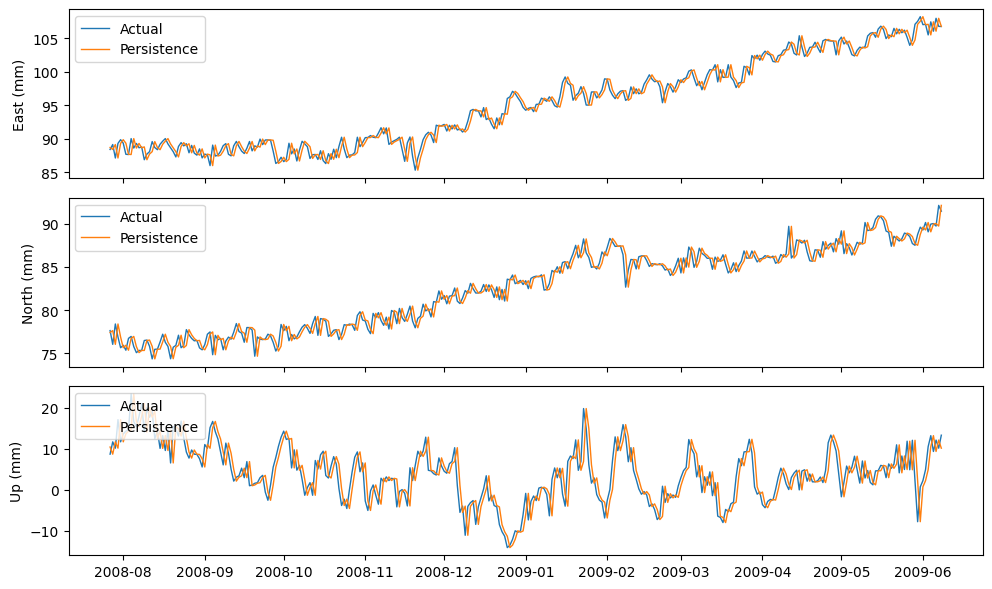

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
0,Persistence,East,1.104260,0.886511,0.938775,0.970187
1,Persistence,North,1.037230,0.802741,0.977936,0.949298
2,Persistence,Up,3.897642,3.100599,217.484449,0.658377


In [4]:
n = len(series)
n_train = int(.70 * n)
n_val = int(.15 * n)
n_select = n_val // 2
select_end = n_train + n_select
cal_end = n_train + n_val
train = series[axes].iloc[:n_train]
select = series[axes].iloc[n_train:select_end]
cal = series[axes].iloc[select_end:cal_end]
test = series[axes].iloc[cal_end:]
assert len(train) >= 730 and len(cal) > 20


split = pd.DataFrame([{'set': name, 'start': part.index[0], 'end': part.index[-1], 'days': len(part)}
                      for name, part in [('training', train), ('selection', select),
                                         ('calibration', cal), ('test', test)]])
save(split, '03_split')
y = series[axes].to_numpy()
select_ids = np.arange(n_train, select_end)
cal_ids = np.arange(select_end, cal_end)
test_ids = np.arange(cal_end, n)
predictions = {'Persistence': series[axes].shift(1).to_numpy()}

fig, ax = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
for a, axis in zip(axes, ax):
    axis.plot(series.index, series[a], lw=.8)
    for day in [select.index[0], cal.index[0], test.index[0]]:
        axis.axvline(day, color='tab:orange', ls='--')
    axis.set_ylabel(a + ' (mm)')
show_plot(fig, '03_split')

# Shared test metrics and plots
metric_rows = []
def evaluate(name):
    actual = y[test_ids]
    pred = predictions[name][test_ids]
    assert np.isfinite(pred).all()
    for j, a in enumerate(axes):
        e = actual[:, j] - pred[:, j]
        valid = np.abs(actual[:, j]) > 1e-6
        metric_rows.append({'model': name, 'axis': a,
                            'root_mean_square_error': np.sqrt(np.mean(e**2)), 'mean_absolute_error': np.mean(np.abs(e)),
                            'mean_absolute_percentage_error': 100*np.mean(np.abs(e[valid]/actual[valid,j])) if valid.any() else np.nan,
                            'coefficient_of_determination': 1 - np.sum(e**2)/np.sum((actual[:,j]-actual[:,j].mean())**2)})
    fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
    for j, axis in enumerate(ax):
        axis.plot(test.index, actual[:,j], label='Actual', lw=1)
        axis.plot(test.index, pred[:,j], label=name, lw=1)
        axis.set_ylabel(axes[j] + ' (mm)')
        axis.legend(loc='upper left')
    show_plot(fig, name + '_test')
    display(pd.DataFrame(metric_rows).query('model == @name'))

evaluate('Persistence')

## Moving average (order q)
Moving average uses past innovations, not a rolling mean of measured coordinates. Choose the order with the smallest selection-period root mean square error among converged training fits. Freeze the parameters and use one-step-ahead state-space predictions.

,model,axis,order,selection_root_mean_square_error
0,Moving average,East,"(0, 0, 5)",4.653031
1,Moving average,North,"(0, 0, 5)",4.256210
2,Moving average,Up,"(0, 0, 4)",4.699249


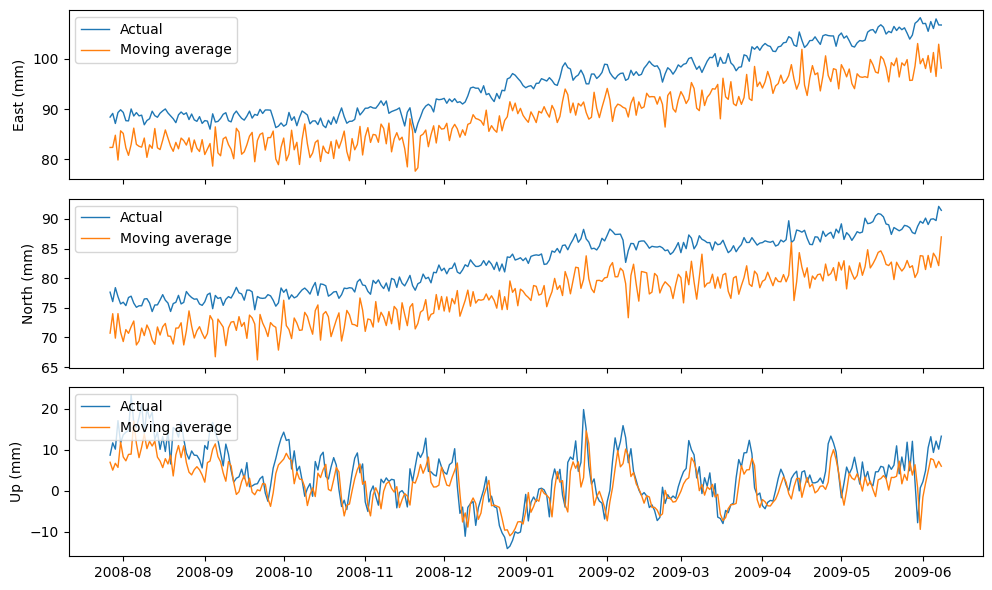

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
3,Moving average,East,6.530919,6.237522,6.529037,-0.042838
4,Moving average,North,6.133223,5.872513,7.095909,-0.772766
5,Moving average,Up,4.441622,3.501095,191.981322,0.556364


In [5]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

def classical(name, orders):
    result = np.full_like(y, np.nan)
    chosen = []
    for j, a in enumerate(axes):
        best = None
        for order in orders:
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', ConvergenceWarning)
                try:
                    fitted = AutoregressiveIntegratedMovingAverage(y[:n_train,j], order=order).fit()
                    if not fitted.mle_retvals.get('converged', True):
                        continue
                    # Parameters are fitted on training only. Filtering gives one-step predictions.
                    model = AutoregressiveIntegratedMovingAverage(y[:,j], order=order)
                    pred = np.asarray(model.filter(fitted.params).get_prediction().predicted_mean)
                    error = np.sqrt(np.mean((y[select_ids,j] - pred[select_ids])**2))
                    if best is None or error < best[0]:
                        best = (error, order, pred)
                except (ValueError, np.linalg.LinAlgError):
                    continue
        if best is None:
            raise RuntimeError('No converged model for ' + name + ' ' + a)
        result[:,j] = best[2]
        chosen.append({'model': name, 'axis': a, 'order': str(best[1]), 'selection_root_mean_square_error': best[0]})
    predictions[name] = result
    save(pd.DataFrame(chosen), name + '_orders')
    evaluate(name)

classical('Moving average', [(0,0,q) for q in range(1,6)])

## Autoregression (order p)
Choose the lag order on the selection set, using the same train-only fitting procedure.

,model,axis,order,selection_root_mean_square_error
0,Autoregression,East,"(5, 0, 0)",1.235845
1,Autoregression,North,"(4, 0, 0)",0.944107
2,Autoregression,Up,"(5, 0, 0)",4.653588


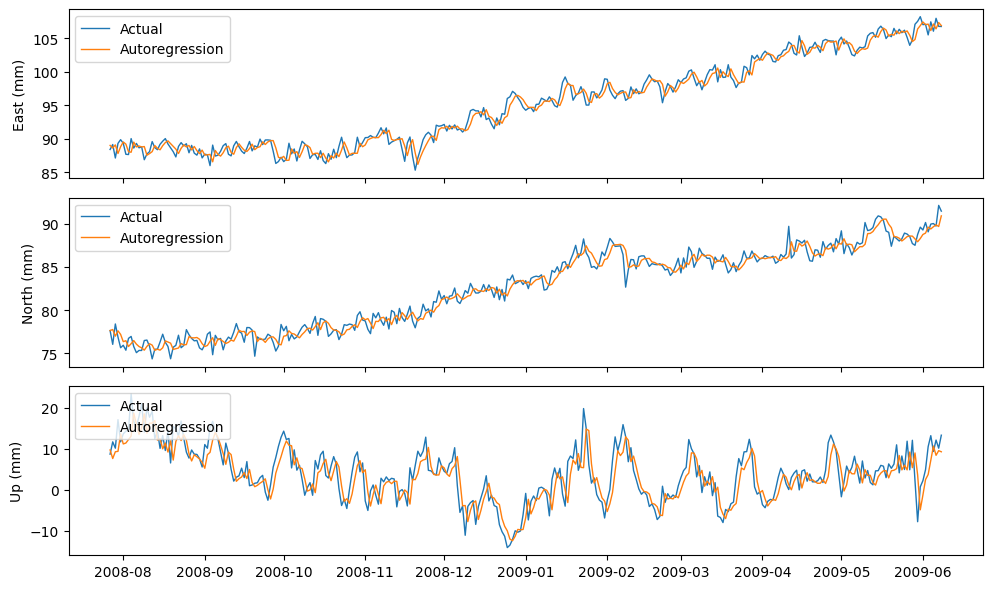

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
6,Autoregression,East,1.047289,0.841018,0.888845,0.973184
7,Autoregression,North,0.941386,0.731714,0.889520,0.958235
8,Autoregression,Up,3.779295,2.995200,199.256710,0.678808


In [6]:
classical('Autoregression', [(p,0,0) for p in range(1,6)])

## Stationarity
Augmented Dickey–Fuller test tests the unit-root null; Kwiatkowski–Phillips–Schmidt–Shin test tests the stationarity null. Augmented Dickey–Fuller test p < 0.05 rejects a unit root; Kwiatkowski–Phillips–Schmidt–Shin test p < 0.05 rejects stationarity.

In [7]:
def stationarity(data, label):
    rows = []
    for a in axes:
        x = data[a].dropna()
        adf = adfuller(x, autolag='AIC')
        k = kpss(x, regression='c', nlags='auto')
        rows.append({'axis': a, 'series': label, 'augmented_dickey_fuller_statistic': adf[0], 'augmented_dickey_fuller_probability': adf[1],
                     'kwiatkowski_phillips_schmidt_shin_statistic': k[0], 'kwiatkowski_phillips_schmidt_shin_probability_bound': k[1]})
    return pd.DataFrame(rows)

levels = stationarity(train, 'level')
save(levels, '06_stationarity')

/tmp/ipykernel_1045/1715588160.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, autolag='AIC')
/tmp/ipykernel_1045/1715588160.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  k = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_1045/1715588160.py:6: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set res

,axis,series,augmented_dickey_fuller_statistic,augmented_dickey_fuller_probability,kwiatkowski_phillips_schmidt_shin_statistic,kwiatkowski_phillips_schmidt_shin_probability_bound
0,East,level,-0.919201,0.781584,5.647130,0.01
1,North,level,-0.570321,0.877548,5.769240,0.01
2,Up,level,-2.643463,0.084343,1.318431,0.01


## Making the data stationary
First difference the coordinates and repeat the tests. Differences describe coordinate changes, not necessarily actual ground motion.

/tmp/ipykernel_1045/1715588160.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(x, autolag='AIC')
/tmp/ipykernel_1045/1715588160.py:6: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  k = kpss(x, regression='c', nlags='auto')
/tmp/ipykernel_1045/1715588160.py:6: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set res

,axis,series,augmented_dickey_fuller_statistic,augmented_dickey_fuller_probability,kwiatkowski_phillips_schmidt_shin_statistic,kwiatkowski_phillips_schmidt_shin_probability_bound
0,East,first difference,-14.422060,7.882142e-27,0.081517,0.1
1,North,first difference,-20.570403,0.000000e+00,0.043141,0.1
2,Up,first difference,-14.159009,2.096960e-26,0.033834,0.1


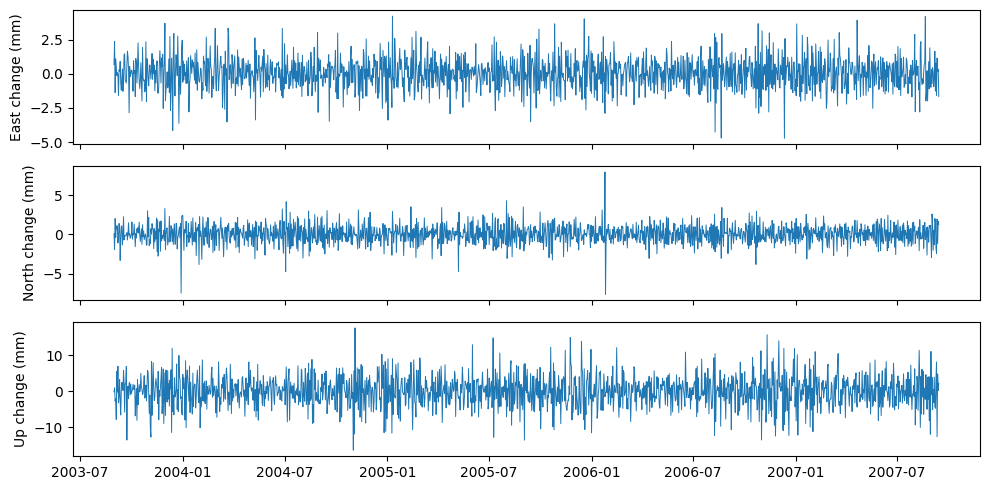

In [8]:
training_differences = train.diff().dropna()
save(stationarity(training_differences, 'first difference'), '07_stationarity_differenced')
fig, ax = plt.subplots(3, 1, figsize=(10,5), sharex=True)
for a, axis in zip(axes, ax):
    axis.plot(training_differences.index, training_differences[a], lw=.7)
    axis.set_ylabel(a + ' change (mm)')
show_plot(fig, '07_differences')

## Autoregressive integrated moving average
Use d=1 based on the differencing diagnostics. Compare small p and q values on the selection set.

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarnin

,model,axis,order,selection_root_mean_square_error
0,Autoregressive integrated moving average,East,"(1, 1, 2)",1.224533
1,Autoregressive integrated moving average,North,"(0, 1, 2)",0.942992
2,Autoregressive integrated moving average,Up,"(2, 1, 2)",4.640607


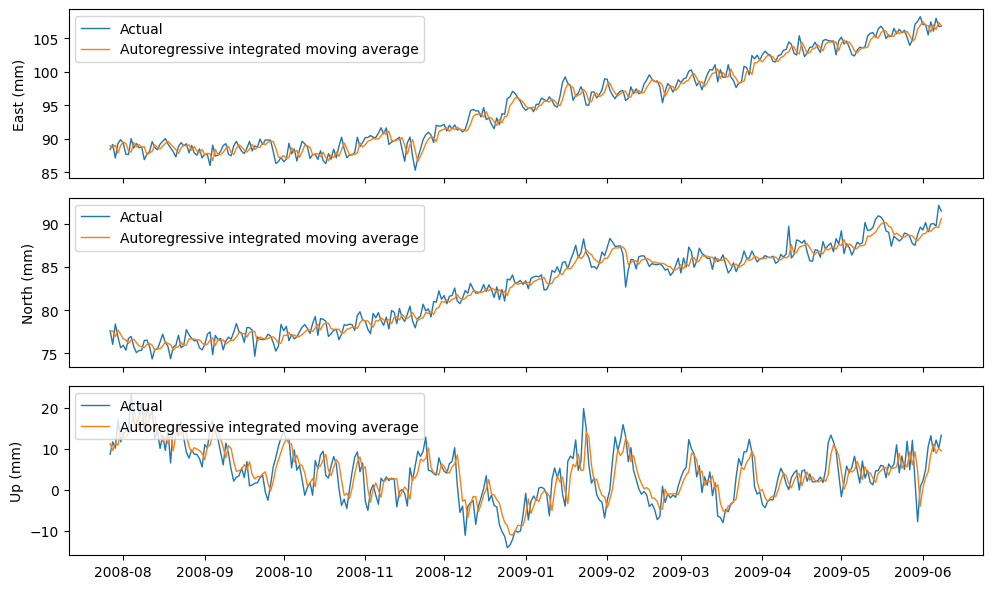

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
9,Autoregressive integrated moving average,East,1.039743,0.836225,0.883660,0.973569
10,Autoregressive integrated moving average,North,0.936178,0.722132,0.876368,0.958696
11,Autoregressive integrated moving average,Up,3.696051,2.935337,181.924343,0.692802


In [9]:
classical('Autoregressive integrated moving average', [(p,1,q) for p in range(3) for q in range(3)])

## Seasonal autoregressive integrated moving average
Fit Seasonal autoregressive integrated moving average(1,1,0)(1,0,0,365) by conditional least squares on training differences. The seasonal Autoregression interaction coefficient is constrained to the product of the two Autoregression coefficients. This avoids fitting a large seasonal state-space model.

,axis,c,phi,Phi
0,East,0.059082,-0.315318,-0.019252
1,North,0.060253,-0.401763,-0.013448
2,Up,-0.001632,-0.257651,0.005745


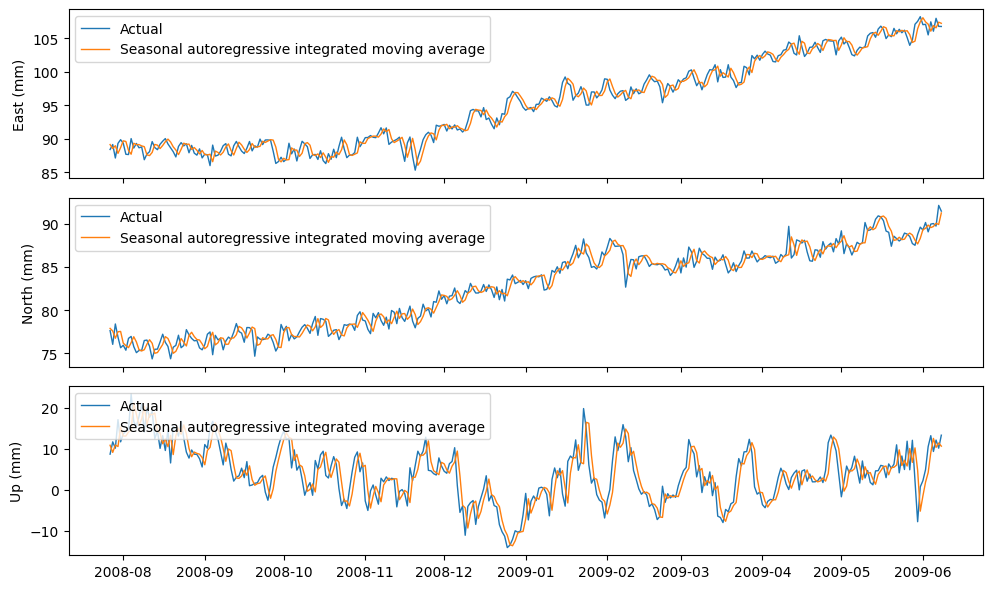

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
12,Seasonal autoregressive integrated moving average,East,1.086093,0.872561,0.923203,0.971160
13,Seasonal autoregressive integrated moving average,North,0.973696,0.754222,0.920423,0.955319
14,Seasonal autoregressive integrated moving average,Up,3.801085,3.002423,224.714450,0.675094


In [10]:
from scipy.optimize import least_squares

z = np.vstack([np.full((1,3), np.nan), np.diff(y, axis=0)])
season = 365
seasonal_prediction = np.full_like(y, np.nan)
season_rows = []
for j, a in enumerate(axes):
    ids = np.arange(season + 2, n_train)
    def increment(theta, t):
        c, phi, Phi = theta
        return c + phi*z[t-1,j] + Phi*z[t-season,j] - phi*Phi*z[t-season-1,j]
    fit = least_squares(lambda theta: z[ids,j] - increment(theta, ids),
                        x0=[0,0,0], bounds=([-np.inf,-.99,-.99],[np.inf,.99,.99]))
    t = np.arange(season+2, n)
    seasonal_prediction[t,j] = y[t-1,j] + increment(fit.x,t)
    season_rows.append({'axis':a, 'c':fit.x[0], 'phi':fit.x[1], 'Phi':fit.x[2]})
predictions['Seasonal autoregressive integrated moving average'] = seasonal_prediction
save(pd.DataFrame(season_rows), 'Seasonal autoregressive integrated moving average_parameters')
evaluate('Seasonal autoregressive integrated moving average')

## Recurrent neural network
Use training-only standardized increments. Try four configurations covering different input lags, batch sizes, learning rates, hidden units and layer counts. Select by validation error. The same helper is reused for long short-term memory and quantile long short-term memory networks.

,lag,batch,learning_rate,units,layers,validation_mean_squared_error
0,15,32,0.0010,16,1,0.880154
1,30,64,0.0010,32,1,0.881876
2,45,128,0.0020,32,2,0.873917
3,30,32,0.0005,48,2,0.879388


Selected: (45, 128, 0.002, 32, 2)


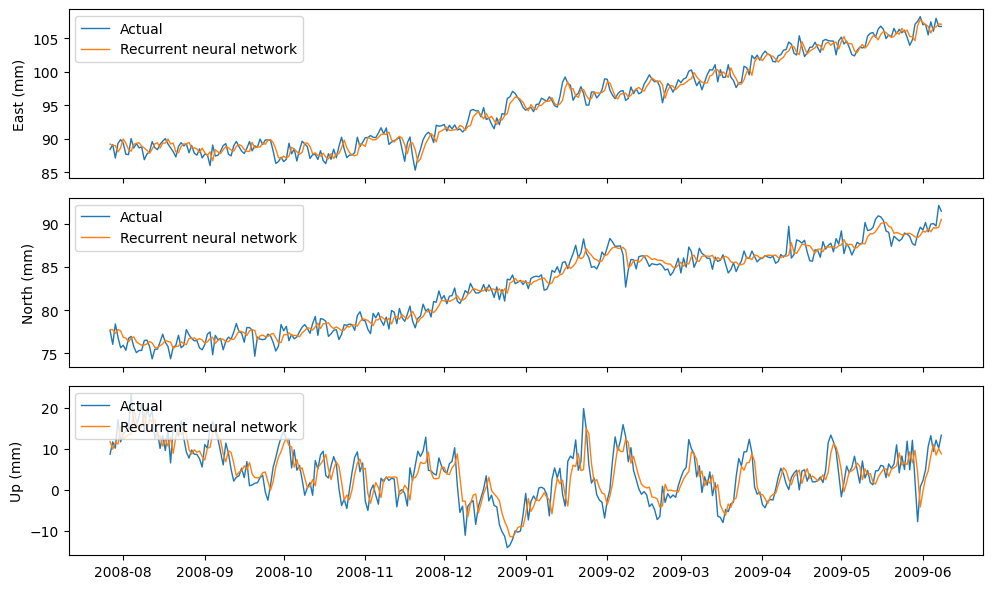

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
15,Recurrent neural network,East,1.011809,0.813311,0.860128,0.974970
16,Recurrent neural network,North,0.935121,0.722344,0.877894,0.958789
17,Recurrent neural network,Up,3.689878,2.943574,192.442109,0.693827


In [11]:
from torch.utils.data import TensorDataset, DataLoader

model_training_changes = series[axes].iloc[:n_train].diff().dropna()
mean = model_training_changes.mean().to_numpy()
scale = model_training_changes.std(ddof=0).to_numpy()
assert np.all(scale > 0)

def windows(values, lag):
    # A forecast requires lag+1 past coordinate levels, not the target value.
    delta = (np.diff(values, axis=0) - mean)/scale
    ids = np.arange(lag+1, len(values))
    x = np.array([delta[t-lag-1:t-1] for t in ids], dtype=np.float32)
    good = np.isfinite(x).all(axis=(1,2))
    return ids[good], x[good]

class Network(nn.Module):
    def __init__(self, kind, hidden, layers):
        super().__init__()
        cell = nn.RNN if kind == 'Recurrent neural network' else nn.LSTM
        self.recurrent_layer = cell(3, hidden, layers, batch_first=True)
        self.fc = nn.Linear(hidden, 3)
    def forward(self, x):
        h, _ = self.recurrent_layer(x)
        return self.fc(h[:, -1])

def train_network(kind, config, quantile=None):
    lag, batch, lr, hidden, layers = config
    torch.manual_seed(42)
    ids, x = windows(y, lag)
    target = (y[ids] - y[ids-1] - mean)/scale
    xt = torch.tensor(x, device=device)
    yt = torch.tensor(target, dtype=torch.float32, device=device)
    tr = ids < n_train
    va = (ids >= n_train) & (ids < select_end)
    loader = DataLoader(TensorDataset(xt[tr],yt[tr]), batch_size=batch, shuffle=True)
    model = Network(kind, hidden, layers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    def loss(pred, actual):
        e = actual - pred
        if quantile is None:
            return (e**2).mean()
        return torch.maximum(quantile*e, (quantile-1)*e).mean()
    best, state, wait = float('inf'), None, 0
    for epoch in range(40):
        model.train()
        for xb,yb in loader:
            optimizer.zero_grad()
            err = loss(model(xb),yb)
            err.backward(); optimizer.step()
        model.eval()
        with torch.no_grad():
            score = loss(model(xt[va]),yt[va]).item()
        if score < best - 1e-6:
            best = score
            state = {k:v.detach().clone() for k,v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
        if wait >= 7:
            break
    model.load_state_dict(state)
    return model, best

def forecast(model, config, values):
    ids, x = windows(values, config[0])
    result = np.full_like(values, np.nan)
    model.eval()
    with torch.no_grad():
        parts = [model(torch.tensor(chunk,device=device)).cpu().numpy()
                 for chunk in np.array_split(x, max(1, int(np.ceil(len(x)/512)))) if len(chunk)]
    if parts:
        result[ids] = values[ids-1] + np.concatenate(parts)*scale + mean
    return result

configs = [(15,32,.001,16,1), (30,64,.001,32,1),
           (45,128,.002,32,2), (30,32,.0005,48,2)]

def tune(kind):
    trials = []
    best_model, best_config, best_score = None, None, float('inf')
    for config in configs:
        model, score = train_network(kind, config)
        trials.append(dict(zip(['lag','batch','learning_rate','units','layers'],config),
                           validation_mean_squared_error=score))
        if score < best_score:
            best_model, best_config, best_score = model, config, score
    save(pd.DataFrame(trials), kind + '_tuning')
    print('Selected:', best_config)
    predictions[kind] = forecast(best_model, best_config, y)
    torch.save(best_model.state_dict(), out / (kind + '.pt'))
    evaluate(kind)
    return best_model, best_config

recurrent_network, recurrent_network_config = tune('Recurrent neural network')

## Long short-term memory
Use exactly the same validation configurations and test dates as the Recurrent neural network. mean absolute percentage error is reported for course compliance but can be unstable for relative coordinates near zero.

,lag,batch,learning_rate,units,layers,validation_mean_squared_error
0,15,32,0.0010,16,1,0.885632
1,30,64,0.0010,32,1,0.875643
2,45,128,0.0020,32,2,0.874523
3,30,32,0.0005,48,2,0.875027


Selected: (45, 128, 0.002, 32, 2)


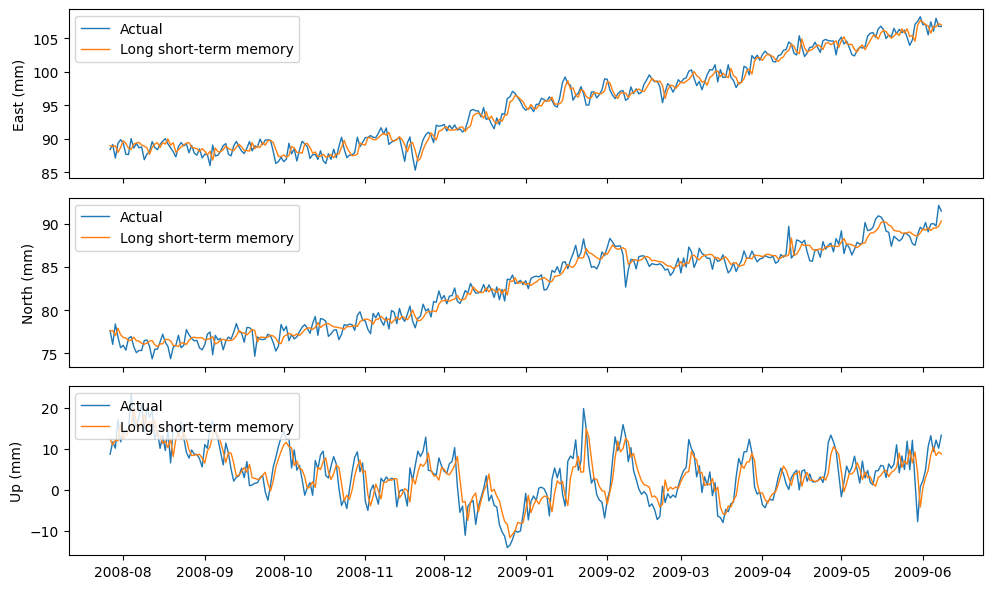

,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
18,Long short-term memory,East,0.994658,0.794476,0.840090,0.975811
19,Long short-term memory,North,0.947258,0.735482,0.894871,0.957713
20,Long short-term memory,Up,3.670431,2.919582,190.272548,0.697046


,model,axis,root_mean_square_error,mean_absolute_error,mean_absolute_percentage_error,coefficient_of_determination
0,Persistence,East,1.104260,0.886511,0.938775,0.970187
1,Persistence,North,1.037230,0.802741,0.977936,0.949298
2,Persistence,Up,3.897642,3.100599,217.484449,0.658377
3,Moving average,East,6.530919,6.237522,6.529037,-0.042838
4,Moving average,North,6.133223,5.872513,7.095909,-0.772766
5,Moving average,Up,4.441622,3.501095,191.981322,0.556364
6,Autoregression,East,1.047289,0.841018,0.888845,0.973184
7,Autoregression,North,0.941386,0.731714,0.889520,0.958235
8,Autoregression,Up,3.779295,2.995200,199.256710,0.678808
9,Autoregressive integrated moving average,East,1.039743,0.836225,0.883660,0.973569


,model,vector_root_mean_square_error_mm
0,Long short-term memory,3.919019
1,Recurrent neural network,3.938706
2,Autoregressive integrated moving average,3.951997
3,Autoregression,4.033124
4,Seasonal autoregressive integrated moving average,4.071355
5,Persistence,4.181728
6,Moving average,9.999867


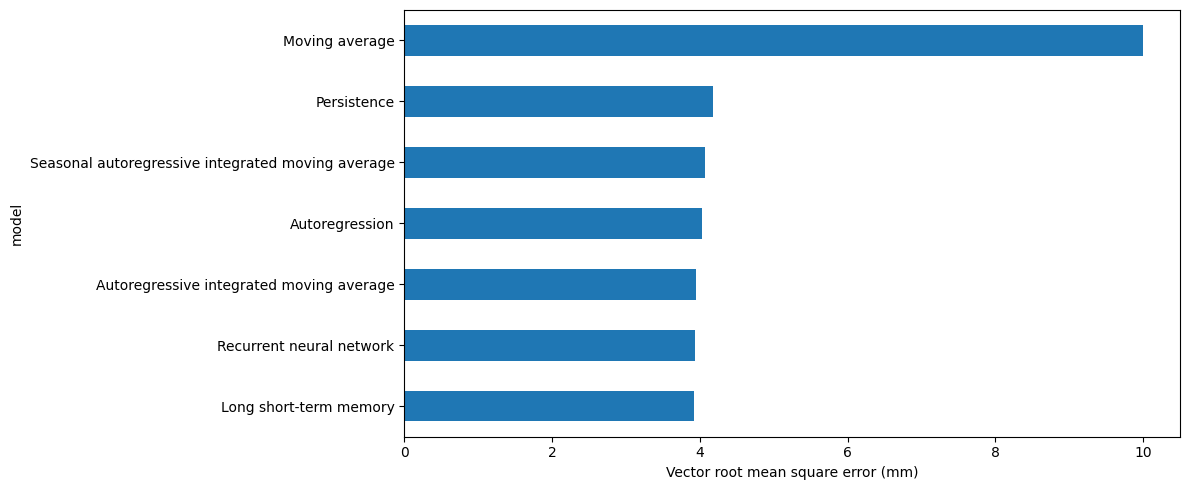

Lowest observed test root mean square error: Long short-term memory


In [12]:
long_short_term_memory, long_short_term_memory_config = tune('Long short-term memory')
metrics = pd.DataFrame(metric_rows)
save(metrics, '11_test_metrics')
summary = metrics.groupby('model').root_mean_square_error.apply(lambda x: np.sqrt(np.sum(x**2))).sort_values()
save(summary.rename('vector_root_mean_square_error_mm').reset_index(), '11_vector_root_mean_square_error')
fig, ax = plt.subplots(figsize=(12,5))
summary.sort_values().plot.barh(ax=ax)
ax.set_xlabel('Vector root mean square error (mm)')
show_plot(fig, '11_model_comparison')
print('Lowest observed test root mean square error:', summary.index[0])

## Forecast to action
The action is to assign routine or detailed technical examination. Flag unusual forecast residuals or poor observation quality. Thresholds are learned from training or reserved calibration data, not from test observations. Missing observations are investigated separately. No automatic coordinate rejection.

In [13]:
quality_cols = ['accepted_hours','accepted_phase_percent','formal_uncertainty_East','formal_uncertainty_North','formal_uncertainty_Up']
low = series.iloc[:n_train][['accepted_hours','accepted_phase_percent']].quantile(.05)
high = series.iloc[:n_train][['formal_uncertainty_East','formal_uncertainty_North','formal_uncertainty_Up']].quantile(.95)

def quality_flag(frame):
    return (frame[quality_cols].isna().any(axis=1) |
            frame[low.index].lt(low).any(axis=1) |
            frame[high.index].gt(high).any(axis=1)).to_numpy()

def joint_cutoff(scores, coverage=.95):
    scores = np.sort(np.asarray(scores)[np.isfinite(scores)])
    k = int(np.ceil((len(scores)+1)*coverage))
    return scores[min(k,len(scores))-1] if len(scores) else np.inf

long_short_term_memory_prediction = predictions['Long short-term memory']
cut = joint_cutoff(np.max(np.abs(y[cal_ids]-long_short_term_memory_prediction[cal_ids])/scale,axis=1))
point_flag = np.max(np.abs(y[test_ids]-long_short_term_memory_prediction[test_ids])/scale,axis=1) > cut
quality_assurance_flag = quality_flag(series)[test_ids]
action = pd.DataFrame({'date':test.index, 'forecast_flag':point_flag, 'quality_assurance_flag':quality_assurance_flag,
                       'action':np.where(point_flag | quality_assurance_flag,'Detailed','Routine')})
save(action, '12_actions')
print(action.action.value_counts())

,date,forecast_flag,quality_assurance_flag,action
0,2008-07-27,False,False,Routine
1,2008-07-28,False,False,Routine
2,2008-07-29,False,False,Routine
3,2008-07-30,False,False,Routine
4,2008-07-31,False,False,Routine
...,...,...,...,...
312,2009-06-04,False,False,Routine
313,2009-06-05,False,False,Routine
314,2009-06-06,False,False,Routine
315,2009-06-07,False,False,Routine


action
Routine     294
Detailed     23
Name: count, dtype: int64


## Probabilistic forecasting
Train two separate Long short-term memory networks for the 0.025 and 0.975 quantiles using pinball loss. Use the selected Long short-term memory configuration, but train each network independently. Sort crossing bounds, then enlarge them if needed using the separate calibration period. Report marginal prediction interval coverage probability and mean prediction interval width for each axis and joint East, North and Up coverage (all three inside).

Crossed test component bounds: 0


,method,axis,prediction_interval_coverage_percent,mean_prediction_interval_width_mm
0,Raw quantiles,East,98.107256,5.175174
1,Raw quantiles,North,95.899054,4.758097
2,Raw quantiles,Up,98.422713,18.169698
3,Raw quantiles,"Joint East, North and Up",92.744479,9.367656
0,Joint calibrated,East,99.684543,5.957265
1,Joint calibrated,North,98.738170,5.581973
2,Joint calibrated,Up,99.369085,21.087464
3,Joint calibrated,"Joint East, North and Up",97.791798,10.875568


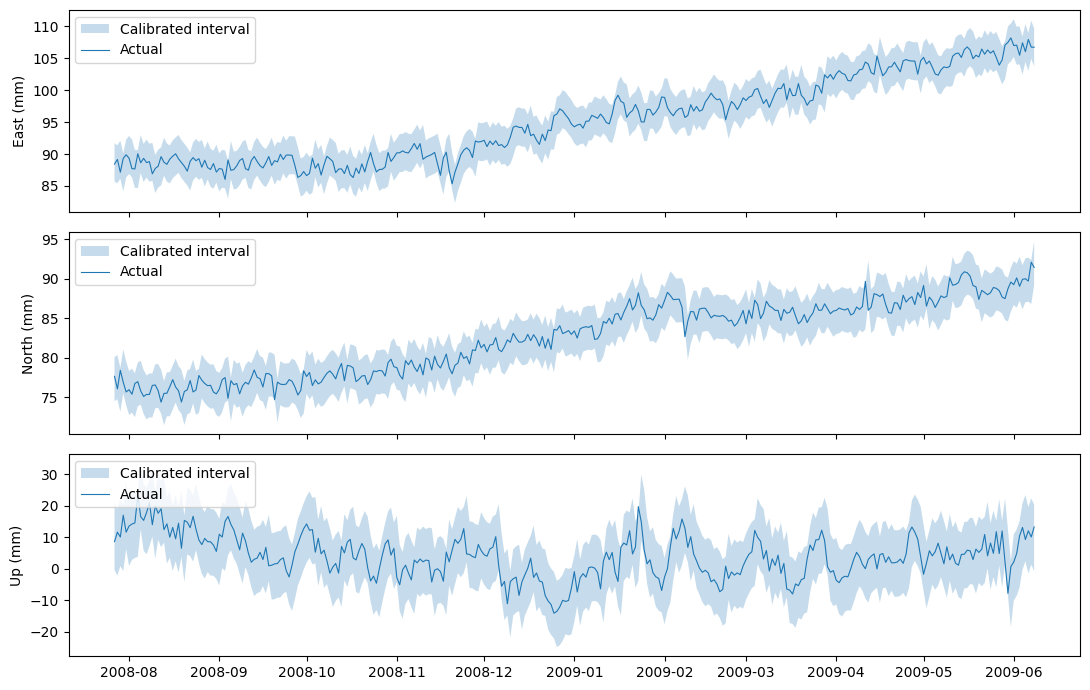

In [14]:
lower_net, _ = train_network('Long short-term memory', long_short_term_memory_config, quantile=.025)
upper_net, _ = train_network('Long short-term memory', long_short_term_memory_config, quantile=.975)
torch.save(lower_net.state_dict(), out / 'lower_quantile_long_short_term_memory.pt')
torch.save(upper_net.state_dict(), out / 'upper_quantile_long_short_term_memory.pt')
a = forecast(lower_net, long_short_term_memory_config, y)
b = forecast(upper_net, long_short_term_memory_config, y)
lo, hi = np.minimum(a,b), np.maximum(a,b)
print('Crossed test component bounds:', (a[test_ids]>b[test_ids]).sum())
scores = np.max(np.maximum(lo[cal_ids]-y[cal_ids], y[cal_ids]-hi[cal_ids])/scale,axis=1)
correction = max(0, joint_cutoff(scores))
cal_lo, cal_hi = lo-correction*scale, hi+correction*scale

def interval_metrics(actual, lower, upper, name):
    assert np.isfinite(lower).all() and np.isfinite(upper).all()
    inside = (actual >= lower) & (actual <= upper)
    width = upper-lower
    rows = [{'method':name,'axis':a,'prediction_interval_coverage_percent':100*inside[:,j].mean(),
             'mean_prediction_interval_width_mm':width[:,j].mean()} for j,a in enumerate(axes)]
    rows.append({'method':name,'axis':'Joint East, North and Up', 'prediction_interval_coverage_percent':100*inside.all(axis=1).mean(),
                 'mean_prediction_interval_width_mm':width.mean()})
    return pd.DataFrame(rows)

save(pd.concat([interval_metrics(y[test_ids],lo[test_ids],hi[test_ids],'Raw quantiles'),
                interval_metrics(y[test_ids],cal_lo[test_ids],cal_hi[test_ids],'Joint calibrated')]),
     '13_interval_metrics')
fig, ax = plt.subplots(3,1,figsize=(11,7),sharex=True)
for j, axis in enumerate(ax):
    axis.fill_between(test.index,cal_lo[test_ids,j],cal_hi[test_ids,j],alpha=.25,label='Calibrated interval')
    axis.plot(test.index,y[test_ids,j],lw=.8,label='Actual')
    axis.set_ylabel(axes[j]+' (mm)'); axis.legend(loc='upper left')
show_plot(fig,'13_prediction_intervals')

interval = pd.DataFrame({'date':test.index})
for j,a in enumerate(axes):
    interval[a] = y[test_ids,j]
    interval['lower_'+a] = cal_lo[test_ids,j]
    interval['upper_'+a] = cal_hi[test_ids,j]
interval.to_csv(out/'13_test_intervals.csv',index=False)

## Risk and reliability
Apply the frozen quantile networks and a calibrated persistence benchmark to the later archive. Compare coverage and review dispositions on recorded data. Forecast issuance and target availability are separate. The review counts describe a retrospective rule, not actual completed examinations. Interval exceedances are not verified faults.

The saved outputs below are from the submitted Colab execution. Review assignments are counted from the daily observations; no assumed examination durations or financial costs are used.


,method,axis,prediction_interval_coverage_percent,mean_prediction_interval_width_mm
0,Quantile long short-term memory,East,98.237410,5.956863
1,Quantile long short-term memory,North,97.913669,5.581712
2,Quantile long short-term memory,Up,98.399281,21.086307
3,Quantile long short-term memory,"Joint East, North and Up",94.946043,10.874961
0,Persistence,East,97.697842,5.541911
1,Persistence,North,98.381295,5.838001
2,Persistence,Up,98.201439,20.675350
3,Persistence,"Joint East, North and Up",94.784173,10.685087


Later calendar days: 6347 Observed: 6266
Issued quantile forecasts: 5574 Common observed dates: 5560


,policy,detailed,routine,missing
0,Review all,6266,0,81
1,Quality assurance + history fallback,2394,3872,81
2,Persistence + quality assurance,2583,3683,81
3,Quantile long short-term memory + quality assu...,2579,3687,81


Additional quantile flags beyond quality and history fallback: 185
Joint interval exceedance (%): 5.05
Interval exceedances are not verified faults.


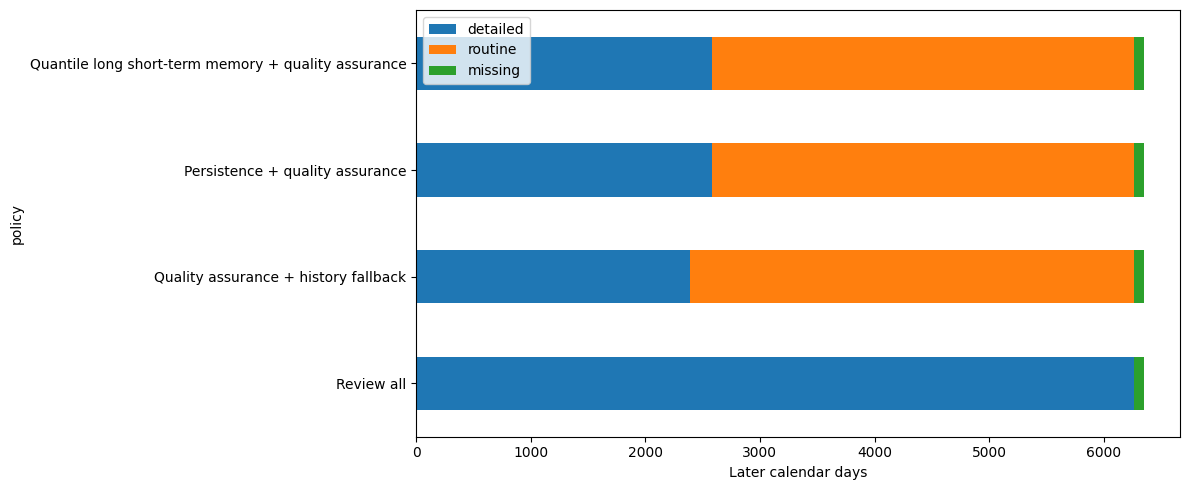

Forecasting and reliability analysis completed.


In [15]:
all_y = calendar[axes].to_numpy()
a = forecast(lower_net,long_short_term_memory_config,all_y)
b = forecast(upper_net,long_short_term_memory_config,all_y)
lo_all = np.minimum(a,b)-correction*scale
hi_all = np.maximum(a,b)+correction*scale
p = calendar[axes].shift(1).to_numpy()
cut_p = joint_cutoff(np.max(np.abs(y[cal_ids]-predictions['Persistence'][cal_ids])/scale,axis=1))
p_lo,p_hi = p-cut_p*scale,p+cut_p*scale
later = calendar.index > series.index[-1]
obs = observed.to_numpy()
issued = np.isfinite(lo_all).all(axis=1) & np.isfinite(hi_all).all(axis=1)
common = later & obs & issued & np.isfinite(p).all(axis=1)
assert common.any()
q_out = ((all_y<lo_all)|(all_y>hi_all)).any(axis=1)
p_out = ((all_y<p_lo)|(all_y>p_hi)).any(axis=1)
quality_assurance = quality_flag(calendar)

reliability = pd.concat([interval_metrics(all_y[common],lo_all[common],hi_all[common],'Quantile long short-term memory'),
                         interval_metrics(all_y[common],p_lo[common],p_hi[common],'Persistence')])
save(reliability,'14_later_coverage')
print('Later calendar days:', later.sum(), 'Observed:', (later & obs).sum())
print('Issued quantile forecasts:', (later & issued).sum(), 'Common observed dates:', common.sum())

# Use the same insufficient-history rule in all three policies for a fair workload comparison.
fallback = obs & ~issued
base = quality_assurance | fallback
policies = {'Review all':np.ones(len(calendar),dtype=bool), 'Quality assurance + history fallback':base,
            'Persistence + quality assurance':base | p_out, 'Quantile long short-term memory + quality assurance':base | q_out}
ledger = pd.DataFrame({'date':calendar.index, 'observed':obs, 'forecast_issued':issued,
                       'common_evaluation':common,'quality_assurance_flag':quality_assurance,'quantile_outside':q_out & obs & issued,
                       'persistence_outside':p_out & obs & np.isfinite(p).all(axis=1)})
rows = []
for name, flag in policies.items():
    detailed = int((later & obs & flag).sum())
    routine = int((later & obs & ~flag).sum())
    missing = int((later & ~obs).sum())
    ledger[name] = np.where(~obs,'Missing',np.where(flag,'Detailed','Routine'))
    rows.append({'policy':name,'detailed':detailed,'routine':routine,'missing':missing})
work = pd.DataFrame(rows)
save(work,'14_workload')
ledger.loc[later].to_csv(out/'14_daily_review.csv',index=False)
extra = int((common & q_out & ~base).sum())
print('Additional quantile flags beyond quality and history fallback:',extra)
print('Joint interval exceedance (%):',round(100*q_out[common].mean(),2))
print('Interval exceedances are not verified faults.')

fig,ax = plt.subplots(figsize=(12,5))
work.set_index('policy')[['detailed','routine','missing']].plot.barh(stacked=True,ax=ax)
ax.set_xlabel('Later calendar days')
show_plot(fig,'14_workload')

# Save all point predictions and the key numerical evidence for the report.
point = pd.DataFrame({'date':test.index})
for j,a in enumerate(axes):
    point['actual_'+a] = y[test_ids,j]
    for name,pred in predictions.items():
        point[name+'_'+a] = pred[test_ids,j]
point.to_csv(out/'all_test_predictions.csv',index=False)
assert set(metrics.model) == {'Persistence','Moving average','Autoregression','Autoregressive integrated moving average','Seasonal autoregressive integrated moving average','Recurrent neural network','Long short-term memory'}
assert len(metrics)==21 and len(test_ids)==len(test)
assert (work.detailed+work.routine+work.missing).eq(later.sum()).all()
print('Forecasting and reliability analysis completed.')

## Export results
The results archive contains two separate folders: exploratory data analysis and forecasting and decision results. The forecasting calculations do not read the exploratory outputs. Save the executed notebook with its outputs.
The results archive contains the outputs of this run. The packaged results have been checked against the displayed tables and saved predictions.


In [16]:
archive = shutil.make_archive('ONSA_GNSS_Results','zip',root_dir=results_folder)
print('Saved:',archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

Saved: /content/ONSA_GNSS_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>